# KMeans — Customer Segmentation

In [35]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
%matplotlib inline

## Load the data

In [36]:
df = pd.read_csv("customers_clusters.csv")

In [37]:
df.head()

,customer_id,annual_income_kusd,spending_score
0,C0001,101.7,96
1,C0002,88.4,86
2,C0003,44.6,32
3,C0004,16.4,75
4,C0005,56.6,48


In [38]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 450 entries, 0 to 449
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer_id         450 non-null    str    
 1   annual_income_kusd  450 non-null    float64
 2   spending_score      450 non-null    int64  
dtypes: float64(1), int64(1), str(1)
memory usage: 10.7 KB


In [40]:
X = df[["annual_income_kusd", "spending_score"]].values   # .values -> NumPy array

Text(0, 0.5, 'Spending score')

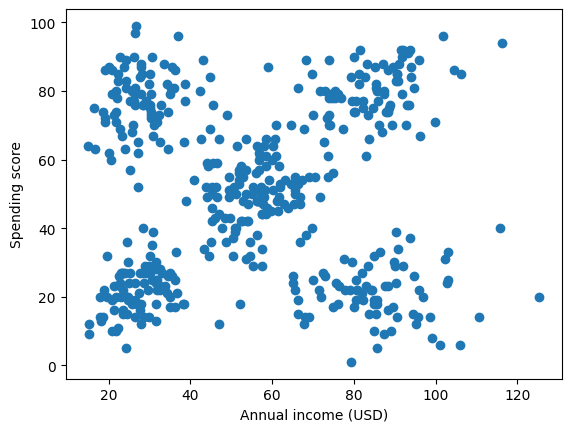

In [41]:
plt.scatter(X[:, 0], X[:, 1])
plt.xlabel("Annual income (USD)")
plt.ylabel("Spending score")

## Standardization — feature scaling

In [42]:
## standardization--feature scaling technique
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [43]:
X_scaled = scaler.fit_transform(X)

In [44]:
from sklearn.cluster import KMeans

In [45]:
## Elbow method To select K Value
wcss = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

In [46]:
print(wcss)

[900.0, 548.5051251059476, 360.6596608010516, 198.97963968001267, 96.82638811123797, 86.32754016520991, 76.7682539969006, 68.64592853564369, 61.447651954031436, 56.18720383036508]


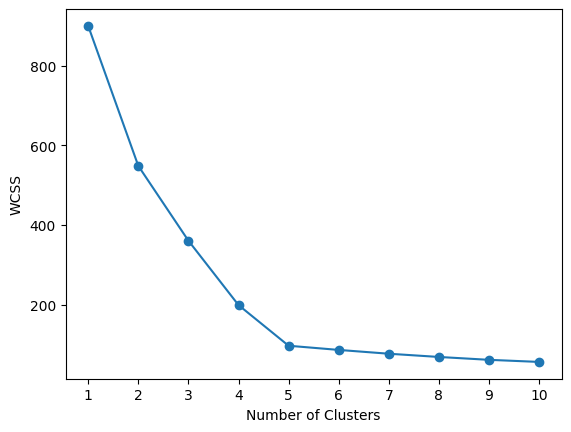

In [47]:
## plot elbow curve
plt.plot(range(1, 11), wcss, marker="o")
plt.xticks(range(1, 11))
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.show()

The curve bends clearly at **k = 5**, then flattens. Let's confirm with the silhouette score,
which unlike WCSS does not automatically improve as k grows.

In [52]:
model = KMeans(n_clusters=5, init="k-means++", n_init=10, random_state=42)
model.fit(X_scaled)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",5
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary `.",42
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'


In [53]:
y_pred = model.predict(X_scaled)
y_pred

array([3, 3, 2, 4, 0, 4, 4, 1, 0, 2, 0, 1, 4, 2, 0, 4, 4, 1, 2, 3, 2, 4,
       1, 3, 2, 0, 0, 3, 1, 1, 3, 4, 0, 2, 3, 0, 2, 0, 2, 1, 1, 4, 1, 3,
       3, 0, 2, 1, 2, 4, 3, 1, 0, 3, 0, 3, 1, 3, 4, 1, 2, 2, 1, 4, 2, 1,
       4, 0, 0, 4, 2, 0, 4, 2, 1, 4, 0, 0, 4, 0, 3, 0, 3, 4, 0, 2, 2, 1,
       2, 1, 2, 0, 4, 2, 3, 2, 0, 3, 2, 2, 0, 1, 0, 0, 0, 4, 1, 3, 3, 1,
       3, 0, 3, 0, 4, 0, 3, 2, 1, 1, 4, 0, 3, 2, 1, 0, 2, 2, 3, 4, 0, 2,
       1, 3, 1, 1, 4, 3, 2, 4, 0, 4, 4, 2, 1, 4, 4, 0, 2, 4, 3, 0, 2, 1,
       1, 2, 3, 0, 0, 0, 2, 1, 0, 0, 0, 0, 4, 3, 0, 2, 0, 4, 1, 3, 0, 3,
       4, 2, 0, 0, 2, 2, 4, 1, 1, 2, 0, 1, 4, 0, 2, 1, 4, 0, 3, 0, 4, 3,
       4, 3, 4, 0, 1, 0, 4, 0, 3, 4, 0, 1, 1, 4, 4, 4, 1, 2, 1, 1, 4, 4,
       3, 0, 1, 2, 4, 0, 2, 1, 3, 4, 1, 1, 2, 3, 0, 1, 4, 0, 2, 2, 0, 3,
       2, 3, 0, 3, 3, 0, 0, 4, 0, 0, 2, 2, 3, 1, 0, 4, 4, 0, 0, 4, 2, 4,
       3, 3, 2, 0, 2, 4, 2, 4, 1, 0, 2, 4, 2, 4, 4, 3, 1, 0, 2, 3, 0, 2,
       0, 3, 0, 3, 2, 3, 2, 4, 0, 3, 0, 3, 2, 1, 1,

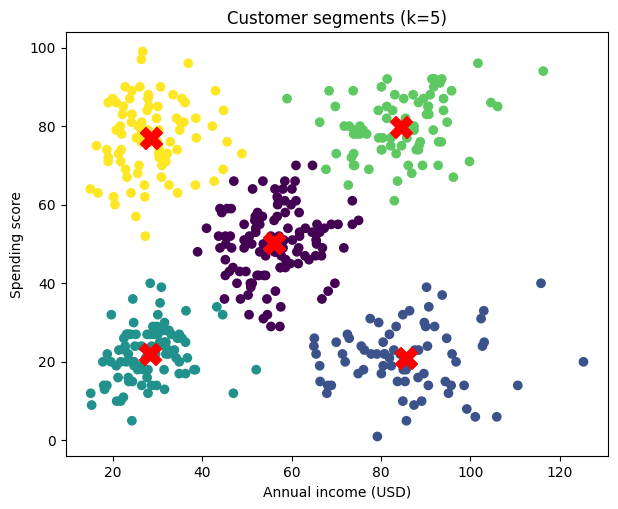

In [54]:
# centroids are in scaled space -> back to real units to read them
centers = scaler.inverse_transform(model.cluster_centers_)

plt.figure(figsize=(7, 5.5))
plt.scatter(X[:, 0], X[:, 1], c=y_pred, cmap="viridis")
plt.scatter(centers[:, 0], centers[:, 1], c="red", marker="X", s=250)
plt.xlabel("Annual income (USD)")
plt.ylabel("Spending score")
plt.title("Customer segments (k=5)")
plt.show()

## Profile the clusters

A cluster number means nothing to a business — describe each group.

In [55]:
df["cluster"] = y_pred

profile = df.groupby("cluster").agg(
    n_customers=("customer_id", "count"),
    avg_income=("annual_income_kusd", "mean"),
    avg_spending=("spending_score", "mean"),
).round(1)
profile

,n_customers,avg_income,avg_spending
cluster,,,
0,119,56.1,50.2
1,75,85.6,20.9
2,90,28.2,22.1
3,80,84.4,79.9
4,86,28.6,76.9


| Cluster profile | Interpretation | Action |
|---|---|---|
| high income, high spending | best customers | loyalty programme, keep them |
| high income, low spending | the money is there, motivation is not | targeted premium offers |
| low income, high spending | enthusiastic, budget-limited | instalments, mid-range promotions |
| low income, low spending | low value today | minimal acquisition spend |
| average / average | the bulk of the base | standard offer |

## Predicting new customers

In [56]:
new_customers = np.array([
    [95000, 85],   # rich and spends a lot
    [24000, 80],   # modest income, spends a lot
    [56000, 48],   # average
])

new_scaled = scaler.transform(new_customers)
model.predict(new_scaled)

array([1, 1, 1], dtype=int32)